# Milestone 2: Detection Dataset Preparation

This notebook prepares a synthetic detection dataset from shared portraits of 13 CelebA identities. It records the source split, generates 640 × 640 frames and YOLO labels, audits the results, and displays annotated examples. Four additional 3 × 3 grids are saved separately.

In [1]:
from pathlib import Path
import os
import shutil
import sys
import pandas as pd
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Start Jupyter from the project root or notebooks directory")
sys.path.insert(0, str(ROOT))

from src.m2_sources import inventory_shared_portraits
from src.m2_detection import build_detection_dataset, audit_detection_dataset

SOURCE_DIR = Path(os.environ.get("M2_SOURCE_DIR", str(ROOT / "data/shared_pool"))).resolve()
M1_MANIFEST = ROOT / "runs/20260926T151014Z_08ffd273/split_manifest.csv"
OUTPUT_DIR = ROOT / "data/m2_detection"
print("Shared source directory available:", SOURCE_DIR.is_dir())
print("Output directory:", OUTPUT_DIR.relative_to(ROOT))

Shared source directory available: True
Output directory: data/m2_detection


## 1. Source images and split

The six Milestone 1 identities retain their recorded source-image splits. The other seven identities use a deterministic split targeting 70/15/15. Each source portrait is assigned before composition and remains in one split.

In [2]:
source_rows, identities = inventory_shared_portraits(SOURCE_DIR, M1_MANIFEST, seed=42)
source_table = pd.DataFrame(source_rows)
display(source_table.groupby(["identity", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]])
display(pd.DataFrame({"class_index": range(len(identities)), "CelebA_ID": identities}))
print("Readable source portraits:", len(source_rows))

split,train,val,test
identity,,,
10002,16,3,4
1212,17,4,4
2336,17,4,4
2619,17,4,4
2970,17,4,4
3,17,4,4
4422,17,4,4
4428,16,3,4
5695,17,4,4


,class_index,CelebA_ID
0,0,3
1,1,7
2,2,797
3,3,1212
4,4,2336
5,5,2619
6,6,2970
7,7,4422
8,8,4428
9,9,5695


Readable source portraits: 319


## 2. Generate frames and YOLO labels

Each 640 × 640 frame combines 2–5 or 9 distinct identities in varied tile sizes and positions over a blurred photo background. Flips and brightness/contrast adjustments vary appearance. YOLO boxes mark the placed portrait regions, and each source photograph remains within one train/validation/test split.

In [3]:
if OUTPUT_DIR.exists():
    print("Reviewing existing output:", OUTPUT_DIR.relative_to(ROOT))
else:
    OUTPUT_DIR, _ = build_detection_dataset(SOURCE_DIR, M1_MANIFEST, OUTPUT_DIR, seed=42)
    print("Generated:", OUTPUT_DIR.relative_to(ROOT))
summary = audit_detection_dataset(OUTPUT_DIR)
ARTIFACT_DIR = ROOT / "m2_artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
for name in ("source_manifest.csv", "object_manifest.csv",
             "identity_mapping.json", "generation_config.json"):
    shutil.copyfile(OUTPUT_DIR / name, ARTIFACT_DIR / name)
display(pd.DataFrame({split: {"frames": values["frames"], "objects": values["objects"]}
                      for split, values in summary.items()}).T)
print("YOLO configuration:", (OUTPUT_DIR / "data.yaml").relative_to(ROOT))
print("Saved manifests and generation settings:", ARTIFACT_DIR.relative_to(ROOT))

Generated: data/m2_detection


,frames,objects
train,156,715
val,39,175
test,39,175


YOLO configuration: data/m2_detection/data.yaml
Saved manifests and generation settings: m2_artifacts


## 3. Verify coverage and annotations

Each image has a matching YOLO text file with one `class_id x_center y_center width height` row per portrait. Coordinates are normalized to the 640 × 640 frame. The audit checks labels, identity coverage, and source-image separation across splits.

In [4]:
coverage = pd.DataFrame({split: values["per_identity"] for split, values in summary.items()}).fillna(0).astype(int)
display(coverage)
label_path = OUTPUT_DIR / "labels/train/train_0000.txt"
print("Example YOLO label:", label_path.relative_to(ROOT))
print(label_path.read_text(encoding="utf-8"))

,train,val,test
3,55,13,14
7,55,13,14
797,55,14,13
1212,55,13,14
2336,55,14,13
2619,55,13,14
2970,55,14,14
4422,55,14,13
4428,55,14,14
5695,55,13,13


Example YOLO label: data/m2_detection/labels/train/train_0000.txt
5 0.255469 0.603125 0.482812 0.650000
7 0.753906 0.532031 0.360938 0.485938



## 4. Inspect generated YOLO boxes

The green rectangles show the YOLO boxes calculated from the placed portrait boundaries. They include one face per portrait but can also include hair, shoulders, and source-image background. These are dataset annotations, not model predictions.

train train_0000_annotated.png


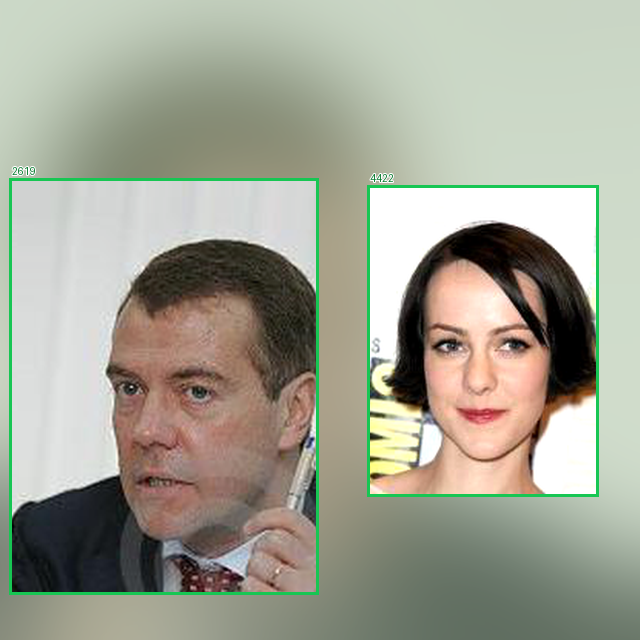

val val_0000_annotated.png


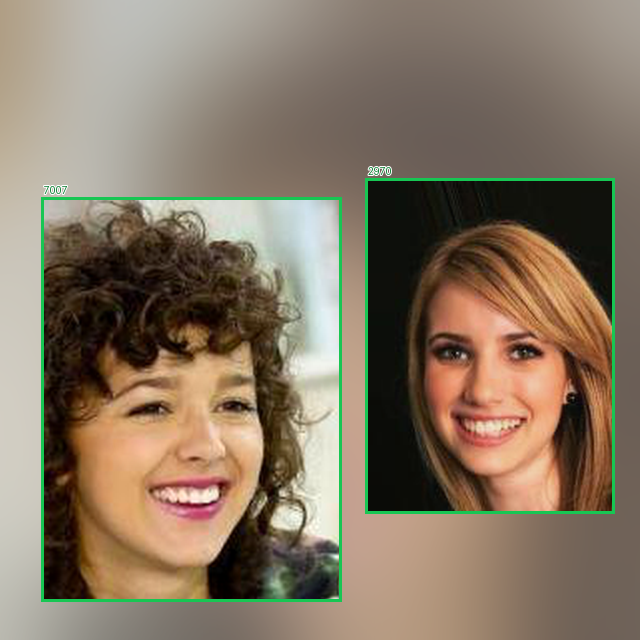

test test_0000_annotated.png


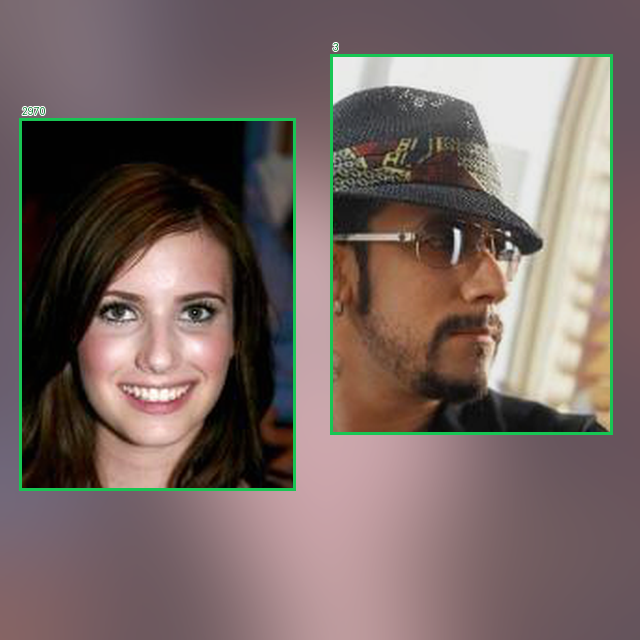

Nine-person training example: train_0004_annotated.png


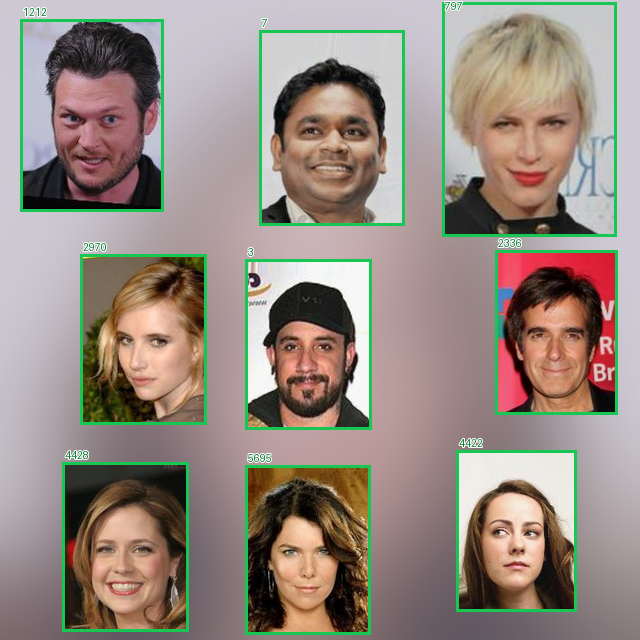

In [5]:
for split in ("train", "val", "test"):
    path = OUTPUT_DIR / "examples" / f"{split}_0000_annotated.png"
    print(split, path.name)
    display(DisplayImage(filename=str(path)))
print("Nine-person training example: train_0004_annotated.png")
display(DisplayImage(filename=str(OUTPUT_DIR / "examples/train_0004_annotated.png")))

## 5. Additional 3 × 3 grids and dataset records

Four additional 640 × 640 grids are saved in `ta_grids/`, separate from the examples above. Matching annotated images are in `ta_grids_annotated/`. The manifests and configuration record the sources, labels, identities, and generation settings.

In [6]:
grid_paths = sorted((OUTPUT_DIR / "ta_grids").glob("grid_*.png"))
print("Additional 3 × 3 grids:", len(grid_paths))
for path in grid_paths:
    print(path.name, "-", path.stat().st_size, "bytes")
print("Source manifest:", (OUTPUT_DIR / "source_manifest.csv").relative_to(ROOT))
print("Object manifest:", (OUTPUT_DIR / "object_manifest.csv").relative_to(ROOT))

Additional 3 × 3 grids: 4
grid_01.png - 445419 bytes
grid_02.png - 427047 bytes
grid_03.png - 428828 bytes
grid_04.png - 440796 bytes
Source manifest: data/m2_detection/source_manifest.csv
Object manifest: data/m2_detection/object_manifest.csv
